# DATAra ML walkthrough

How DATAra's forecast works, from features to evaluation to the forecast the phone makes, shown with the final model `final-2026-11-17`.

This notebook **calls the real pipeline code** (`datara_ml`) and reads the committed results in `artifacts/`; it does not retrain anything or re-implement any rule. It never opens the raw harvester exports in `data/` (RA 10173), so it runs on any clone of this repository.

To reproduce the numbers themselves, run the pipeline in the README (`features` → `train_v0` → `evaluate`). To run this notebook: `pip install -r requirements.txt jupyter`, then open it from the repository root or from `notebooks/`.

In [1]:
import json, math, sys
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import onnxruntime as ort
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from datara_ml import features as F

ART = ROOT / "artifacts"
EVAL = ART / "eval"
report = json.loads((EVAL / "report.json").read_text(encoding="utf-8"))
train_report = json.loads((ART / "v0_report.json").read_text(encoding="utf-8"))
fixture = json.loads((ART / "golden_parity.json").read_text(encoding="utf-8"))
PH = timezone(timedelta(hours=8))
ph_time = lambda ms: datetime.fromtimestamp(ms / 1000, PH).strftime("%b %d, %Y %H:%M")
pd.set_option("display.precision", 2)
print("Model:", train_report["model_version"], "| feature contract v%d" % F.CONTRACT_VERSION)

Model: final-2026-11-17 | feature contract v4


## 1. The data

Volunteers ran the separate **data-harvester** app, which logged mobile usage every 30 seconds and NetworkStatsManager totals every 10 minutes, with signal strength, network type and carrier. Cleaning (B1) repaired counter spikes from harvester ≤ 1.6.7, and hourly usage comes from NetworkStatsManager because the 30-second readings miss about a quarter of usage (see `docs/measurement-gaps.md`).

One training row = one device-hour that the app could have forecast (at least 6 of the previous 24 hours measured, the same rule as the app's "Collecting usage" state).

In [2]:
pd.Series({
    "Training rows (device-hours)": f"{report['rows']:,}",
    "Devices": report["devices"],
    "First hour (PH time)": ph_time(report["hours_from"]),
    "Last hour (PH time)": ph_time(report["hours_to"]),
    "Validation": report["cv"],
}).to_frame("value")

,value
Training rows (device-hours),"2,672"
Devices,20
First hour (PH time),"Oct 30, 2026 00:00"
Last hour (PH time),"Nov 17, 2026 12:00"
Validation,5-fold grouped by device (train_v0.device_fold...


## 2. Features (contract v4)

Twelve features, each computable on the phone at the start of the hour from the same readings. The app's `FeatureExtractor` reproduces `datara_ml/features.py` exactly (checked in section 9). Byte features are `log1p(bytes)`.

In [3]:
about = {
    "hour_sin": "Hour of day (cyclical, sine)",
    "hour_cos": "Hour of day (cyclical, cosine)",
    "day_of_week": "0 = Monday … 6 = Sunday",
    "is_weekend": "1 on Saturday and Sunday",
    "log_bytes_last_1h": "Usage in the last hour",
    "log_avg_bytes_last_3h": "Average usage over the last 3 hours",
    "log_avg_bytes_last_24h": "Average usage over the last 24 hours",
    "log_bytes_same_hour_yesterday": "Usage in the same hour yesterday",
    "log_bytes_same_hour_last_week": "Usage in the same hour a week ago",
    "signal_dbm_last_hour": "Median signal strength last hour (dBm)",
    "radio_gen_last_hour": "Network generation last hour (2G–5G)",
    "cellular_share_last_hour": "Share of last hour's readings on mobile data",
}
pd.DataFrame({"feature": F.FEATURES, "meaning": [about[f] for f in F.FEATURES]}, index=range(1, F.N_FEATURES + 1))

,feature,meaning
1,hour_sin,"Hour of day (cyclical, sine)"
2,hour_cos,"Hour of day (cyclical, cosine)"
3,day_of_week,0 = Monday … 6 = Sunday
4,is_weekend,1 on Saturday and Sunday
5,log_bytes_last_1h,Usage in the last hour
6,log_avg_bytes_last_3h,Average usage over the last 3 hours
7,log_avg_bytes_last_24h,Average usage over the last 24 hours
8,log_bytes_same_hour_yesterday,Usage in the same hour yesterday
9,log_bytes_same_hour_last_week,Usage in the same hour a week ago
10,signal_dbm_last_hour,Median signal strength last hour (dBm)


## 3. The model

**Target:** mobile bytes used in the **next hour** (ROADMAP Decision 2). The PET is not a label: the app projects hour-by-hour predictions against the remaining quota.

**XGBoost with the Tweedie objective** predicts the mean usage of an hour, which handles the many zero hours. Hyperparameters were chosen by **PET error** on simulated quota cycles, inside **nested cross-validation grouped by device**: every score below is on phones the model never saw in training.

In [4]:
p = train_report["params"]
display(pd.Series({
    "Objective": train_report["objective"],
    "Tweedie variance power": p["tweedie_variance_power"],
    "Max depth": p["max_depth"],
    "Trees": p["n_estimators"],
    "Learning rate": p["learning_rate"],
    "Selected by": train_report["selection"],
}).to_frame("final model"))
pd.DataFrame(report["params_per_fold"], index=[f"fold {i}" for i in range(1, 6)]).rename_axis("chosen inside each outer fold")

,final model
Objective,tweedie
Tweedie variance power,1.5
Max depth,2
Trees,150
Learning rate,0.05
Selected by,pet_mae


,tweedie_variance_power,max_depth,n_estimators
chosen inside each outer fold,,,
fold 1,1.3,3,150
fold 2,1.5,2,150
fold 3,1.5,2,150
fold 4,1.1,2,150
fold 5,1.3,2,150


## 4. Next-hour error

Compared with a **linear regression** on the same 12 features (fitted on the same training phones; the simple learned model) and three simple baselines, all scored on the same held-out hours.

In [5]:
names = {"global": "Global XGBoost (Tweedie)", "linear": "Linear regression", "last_hour": "Last hour", "last_24h_avg": "Average of last 24 h",
         "same_hour_yesterday": "Same hour yesterday"}
nh = pd.DataFrame(report["next_hour"]).T.rename(index=names)
nh[["mae_mb", "rmse_mb", "r2", "pred_over_actual"]].rename(columns={
    "mae_mb": "MAE (MB)", "rmse_mb": "RMSE (MB)", "r2": "R²", "pred_over_actual": "Predicted ÷ actual total"}).astype(float).round(2)

,MAE (MB),RMSE (MB),R²,Predicted ÷ actual total
Global XGBoost (Tweedie),45.97,114.14,0.29,0.90
Linear regression,59.53,123.91,0.17,1.09
Last hour,48.32,135.29,0.01,0.99
Average of last 24 h,56.24,122.29,0.19,1.10
Same hour yesterday,68.15,161.05,-0.41,1.18


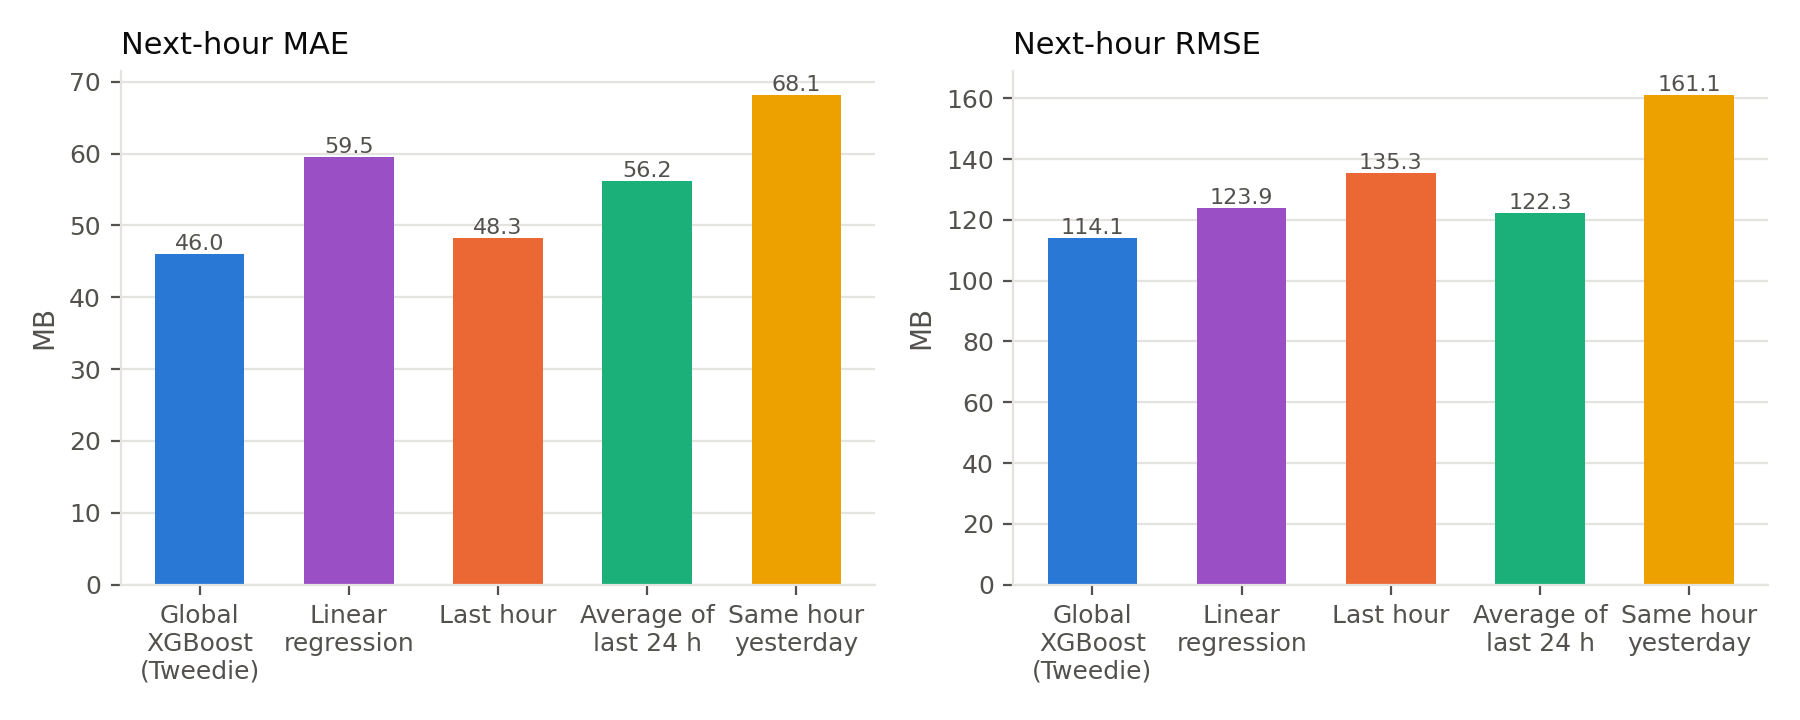

In [6]:
display(Image(filename=str(EVAL / "next_hour_error.png")))

## 5. PET error (the thesis metric)

The harvester data has no user-set quotas, so quota cycles are **simulated** on held-out phones: start at every hour the app would show a forecast, with quotas of 100 MB, 500 MB, 1 GB and 3 GB, run the app's projection, and compare the projected PET with the hour measured usage actually crossed the quota. Error = projected − actual (negative = early).

In [7]:
rows = []
for q, label in [("100", "100 MB"), ("500", "500 MB"), ("1000", "1 GB"), ("3000", "3 GB"), ("all", "All")]:
    for m in ["global", "linear", "last_24h_avg", "last_hour"]:
        r = report["pet"][q][m]
        rows.append({"quota": label, "method": names[m], "cycles": r["n"], "MAE (h)": r["mae_h"],
                     "median abs (h)": r["median_abs_h"], "within ±24 h": f"{r['within_24h']:.0%}",
                     "bias (h)": r["bias_h"], "beyond 30 days": r["beyond_horizon"]})
pd.DataFrame(rows).set_index(["quota", "method"])

cycles  MAE (h)  median abs (h) within ±24 h  \
quota  method                                                                   
100 MB Global XGBoost (Tweedie)    1393     5.67            1.23          93%   
       Linear regression           1393    22.21            1.16          91%   
       Average of last 24 h        1393    64.56            1.78          84%   
       Last hour                   1393   225.27            4.51          63%   
500 MB Global XGBoost (Tweedie)    1016     9.79            4.86          88%   
       Linear regression           1016    32.95            4.27          81%   
       Average of last 24 h        1016    86.74            8.38          71%   
       Last hour                   1016   268.78           25.12          50%   
1 GB   Global XGBoost (Tweedie)     736    12.71            8.01          84%   
       Linear regression            736    43.88            8.16          72%   
       Average of last 24 h         736   100.39           12.76          65%   
       Last hour                    736   285.46           43.82          43%   
3 GB   Global XGBoost (Tweedie)     373    23.18           17.80          61%   
       Linear regression            373    31.38           20.03          60%   
       Average of last 24 h         373    73.66           21.72          54%   
       Last hour                    373   312.70          142.79          26%   
All    Global XGBoost (Tweedie)    3518    10.19            4.04          86%   
       Linear regression           3518    30.82            4.49          81%   
       Average of last 24 h        3518    79.43            6.14          73%   
       Last hour                   3518   259.70           21.71          51%   

                                 bias (h)  beyond 30 days  
quota  method                                              
100 MB Global XGBoost (Tweedie)     -4.77               0  
       Linear regression            11.52              32  
       Average of last 24 h         57.96             111  
       Last hour                   223.16             428  
500 MB Global XGBoost (Tweedie)     -5.89               0  
       Linear regression            13.61              32  
       Average of last 24 h         76.07              94  
       Last hour                   263.93             367  
1 GB   Global XGBoost (Tweedie)     -6.39               0  
       Linear regression            16.34              31  
       Average of last 24 h         88.67              87  
       Last hour                   278.34             278  
3 GB   Global XGBoost (Tweedie)    -11.08               0  
       Linear regression           -27.68               0  
       Average of last 24 h         50.57              16  
       Last hour                   295.56             155  
All    Global XGBoost (Tweedie)     -6.10               0  
       Linear regression             8.98              95  
       Average of last 24 h         68.83             308  
       Last hour                   254.15            1228

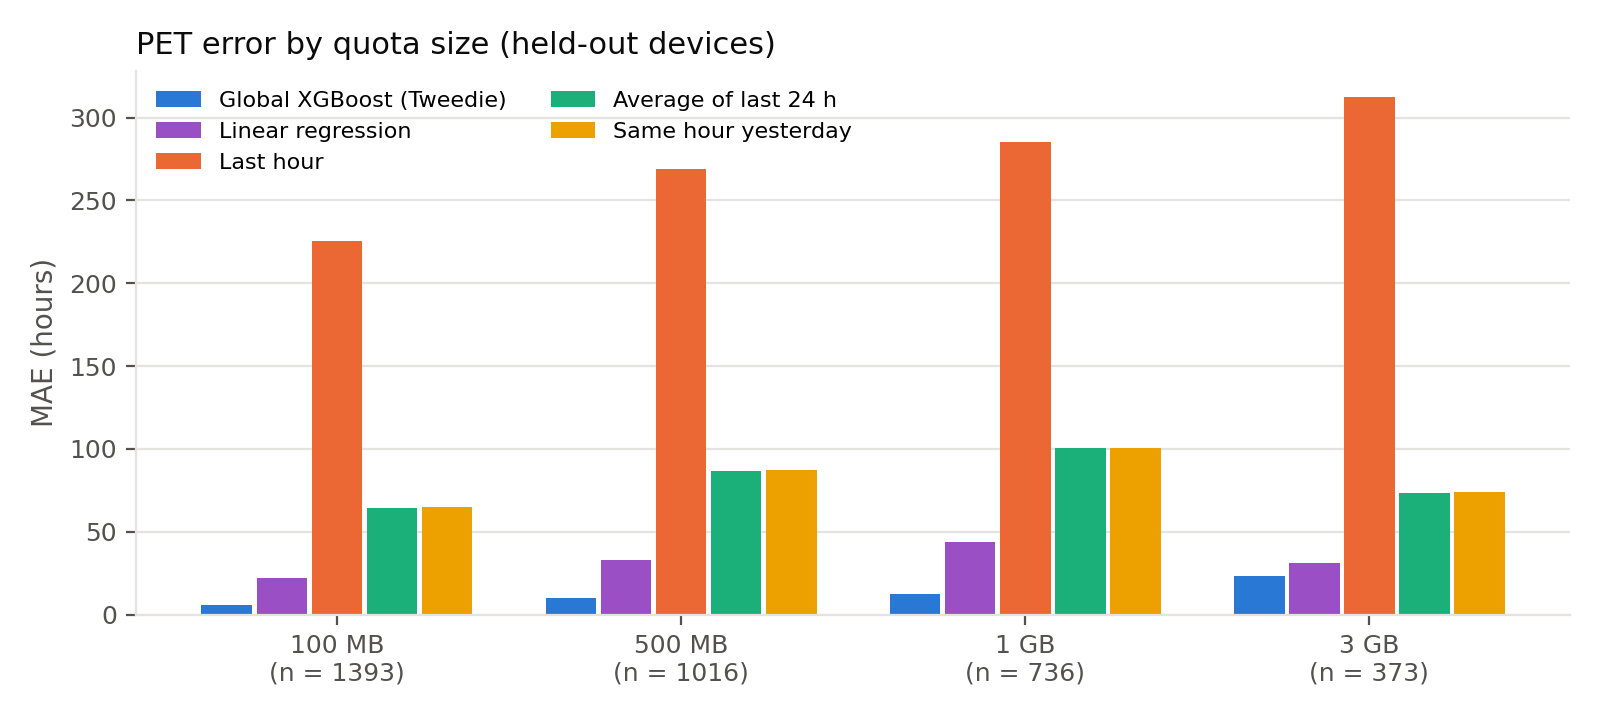

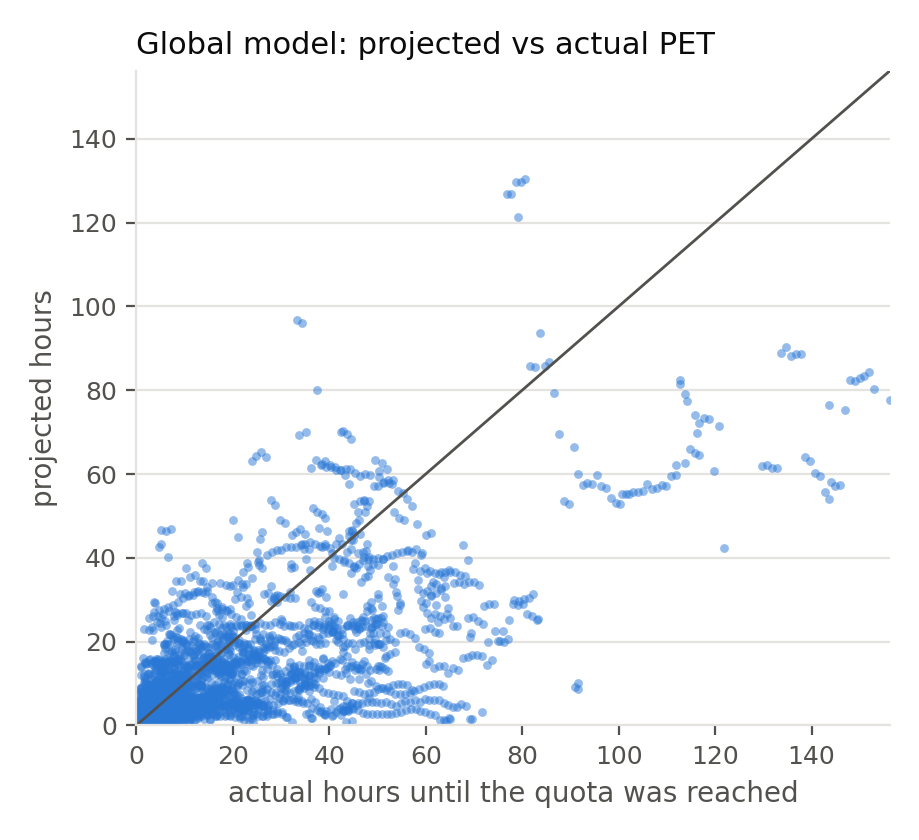

In [8]:
display(Image(filename=str(EVAL / "pet_mae_by_quota.png")))
display(Image(filename=str(EVAL / "pet_projected_vs_actual.png")))

## 6. Forecast alerts as classification

The app warns when the PET is within 24 h or 3 h. At every start hour and quota, that is a yes/no prediction ("the quota will be reached within W hours"), scored against whether measured usage really reached it. **Precision:** when it warned, was it right? **Recall:** of the times the quota was about to be reached, how often did it warn?

In [9]:
for w in ["24h", "3h"]:
    g = report["alerts"][w]["all"]["global"]
    print(f"Within {w}, Global model, all quotas ({report['alerts'][w]['all']['labelled']:,} labelled starts)")
    display(pd.DataFrame([[g["tp"], g["fp"]], [g["fn"], g["tn"]]],
                         index=["Alert", "No alert"], columns=["Actually reached", "Not reached"]))
    display(pd.DataFrame({names[m]: {k: report["alerts"][w]["all"][m][k] for k in ["precision", "recall", "f1", "specificity"]}
                          for m in ["global", "linear", "last_24h_avg", "last_hour"]}).T)

Within 24h, Global model, all quotas (6,626 labelled starts)


,Actually reached,Not reached
Alert,2842,1972
No alert,111,1701


,precision,recall,f1,specificity
Global XGBoost (Tweedie),0.59,0.96,0.73,0.46
Linear regression,0.60,0.96,0.74,0.49
Average of last 24 h,0.78,0.84,0.81,0.81
Last hour,0.84,0.61,0.70,0.91


Within 3h, Global model, all quotas (9,663 labelled starts)


,Actually reached,Not reached
Alert,803,562
No alert,270,8028


,precision,recall,f1,specificity
Global XGBoost (Tweedie),0.59,0.75,0.66,0.93
Linear regression,0.42,0.71,0.53,0.88
Average of last 24 h,0.57,0.73,0.64,0.93
Last hour,0.66,0.63,0.65,0.96


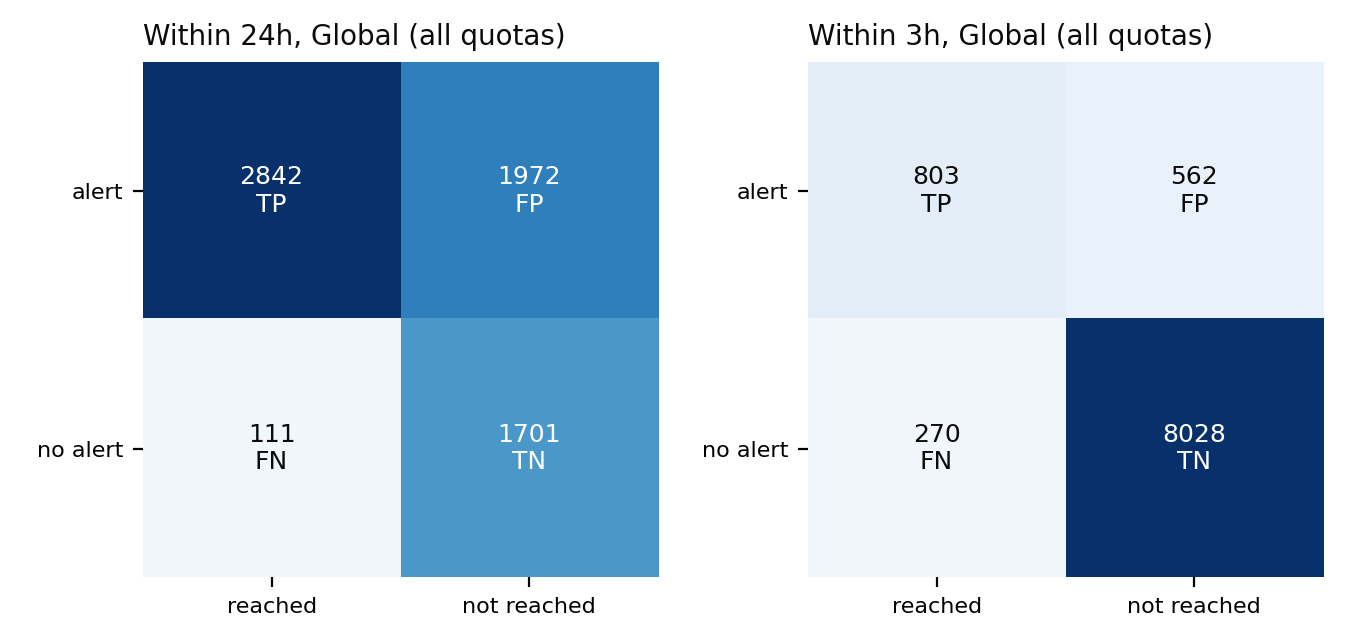

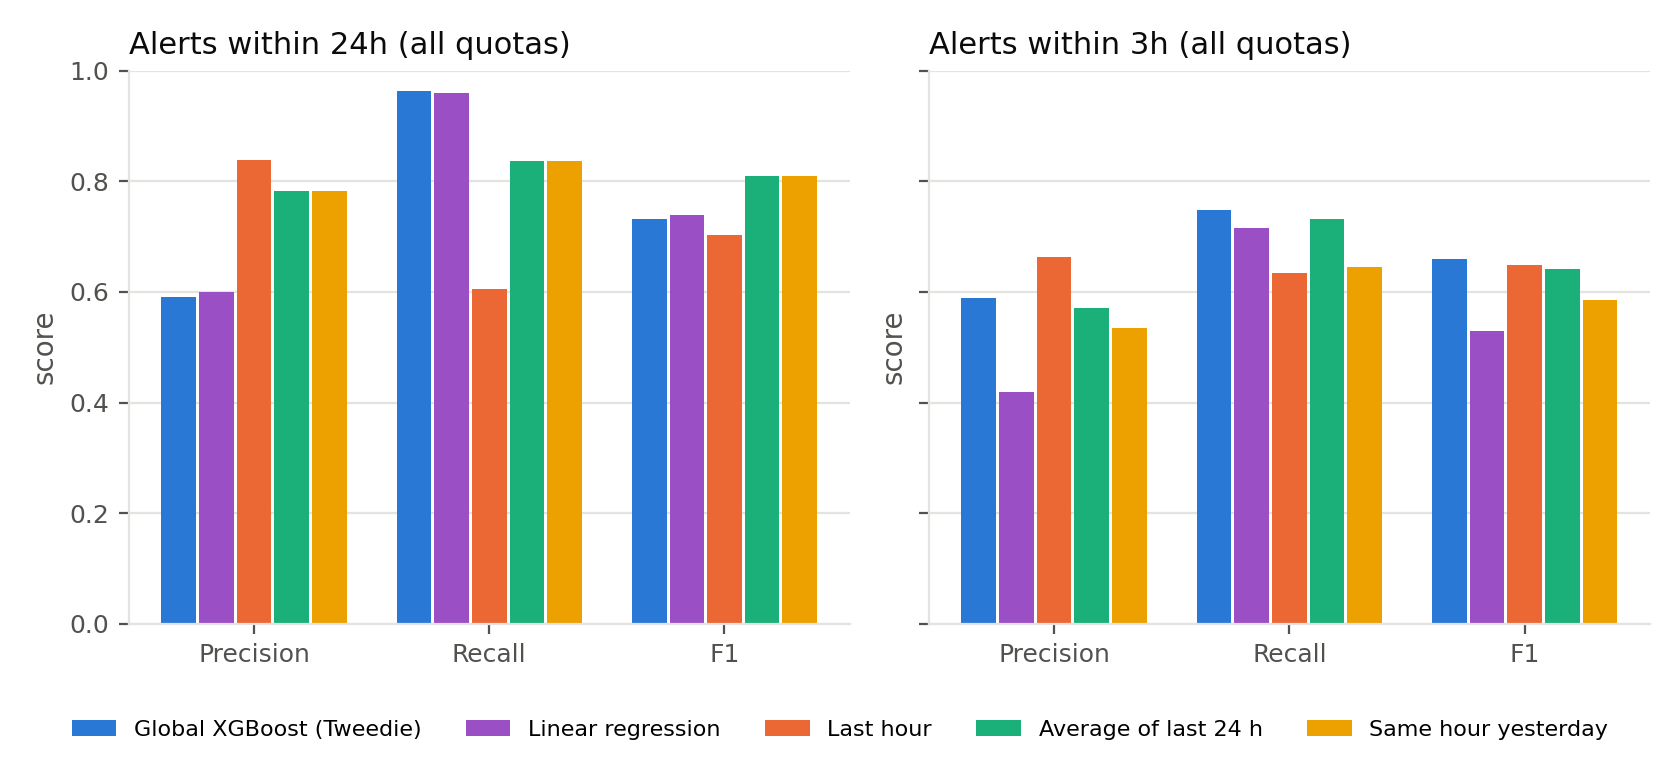

In [10]:
display(Image(filename=str(EVAL / "alert_confusion.png")))
display(Image(filename=str(EVAL / "alert_scores.png")))

## 7. E3: Global vs Local

The app's local layer (a usage-ratio correction per 6-hour block, learned on the phone) is replayed hour by hour on each held-out phone. It takes over after 168 learned hours when its recent error is at least 5% lower than Global's, and switches back when it is not.

In [11]:
e3 = report["e3"]
display(pd.Series({
    "Devices with ≥ 168 learned hours": f"{e3['devices_reaching_168_learned_hours']} of {report['devices']}",
    "Devices that switched to Local": e3["devices_switched_to_local"],
    "Hours shown as Local": e3["rows_local_active"],
}).to_frame("value"))
lab = {"global": "Global only", "local_switched": "With the switch (what users saw)",
       "global_on_ready": "Global, where local was ready", "local_shadow": "Local, where it was ready"}
pd.DataFrame({lab[k]: {"PET MAE (h)": v["mae_h"], "within ±24 h": f"{v['within_24h']:.0%}", "cycles": v["n"]}
              for k, v in {**e3["pet"]["all"], **e3["pet_when_local_ready"]["all"]}.items()}).T

,value
Devices with ≥ 168 learned hours,6 of 20
Devices that switched to Local,3
Hours shown as Local,309


,PET MAE (h),within ±24 h,cycles
Global only,10.47,87%,2895
With the switch (what users saw),10.07,86%,3518
"Local, where it was ready",11.37,86%,2895


## 8. Feature importance

Gain share of each feature in the final model: recent usage dominates; time of day and the network features add the rest.

,gain share
log_bytes_last_1h,0.39
log_avg_bytes_last_3h,0.24
log_avg_bytes_last_24h,0.11
hour_cos,0.04
log_bytes_same_hour_yesterday,0.04
log_bytes_same_hour_last_week,0.04
hour_sin,0.03
cellular_share_last_hour,0.03
signal_dbm_last_hour,0.03
radio_gen_last_hour,0.03


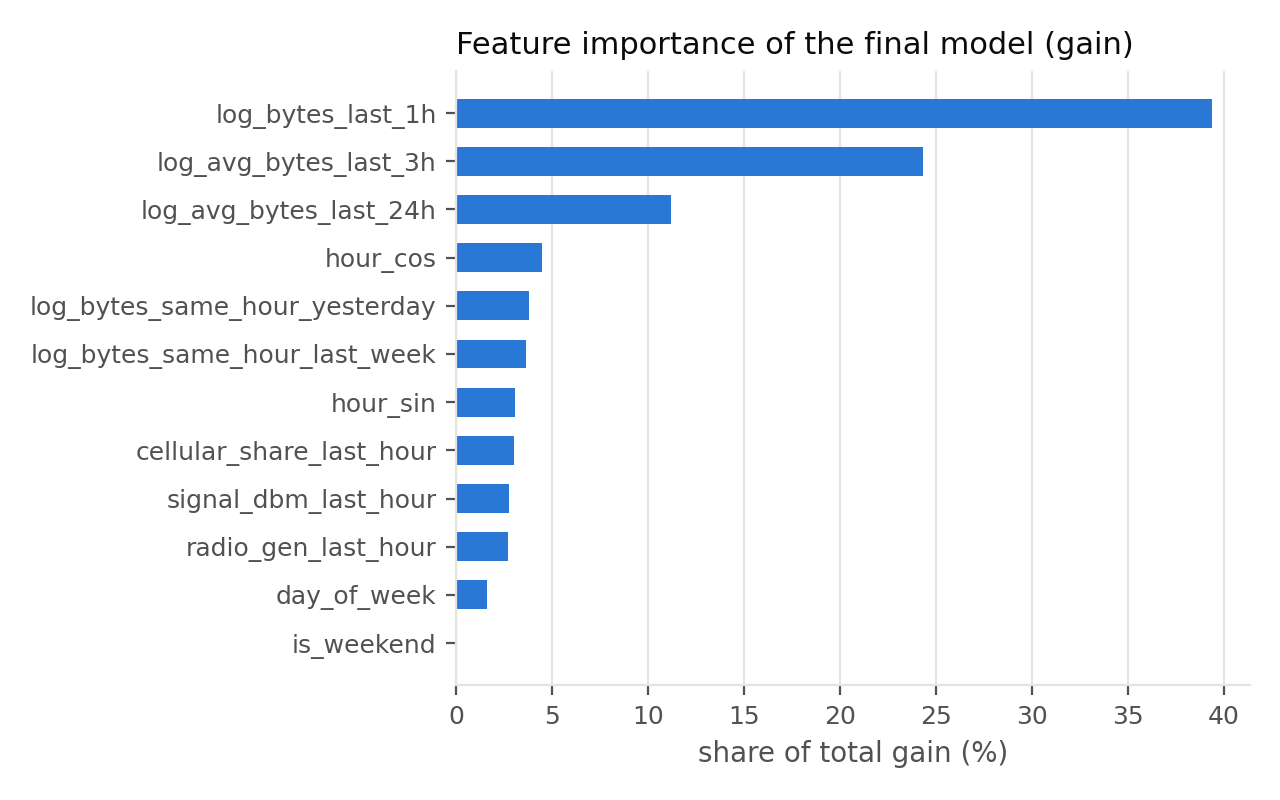

In [12]:
display(pd.Series(report["importance"]["gain_share"], name="gain share").to_frame())
display(Image(filename=str(EVAL / "feature_importance.png")))

## 9. One forecast, the way the phone makes it

The app ships `global_xgboost.onnx` and runs it with ONNX Runtime. Here the same file runs on one test history from the parity fixture (`golden_parity.json`, the file the app's `FeatureParityTest` replays): the Python features match the fixture, ONNX gives the fixture's prediction, and `features.project` turns it into a PET for a 1 GB remaining quota, exactly as the app does.

In [13]:
case = fixture["cases"][0]
history = {h["hour_start_ms"]: F.HourStats(
    mobile_bytes=h["mobile_bytes"], readings=h["readings"], cellular_readings=h["cellular_readings"],
    signal_dbm=math.nan if h["signal_dbm"] is None else h["signal_dbm"], radio=tuple(h["radio"]))
    for h in case["history"]}
t = case["forecast_hour_ms"]
x = F.feature_vector(history, t)
print("Forecast hour:", ph_time(t), "|", len(history), "measured hours of history")
display(pd.DataFrame({"python": x, "fixture (app must match)": case["expected_features"]}, index=F.FEATURES))

session = ort.InferenceSession(str(ART / "global_xgboost.onnx"))
predict = lambda row: F.to_bytes(float(session.run(None, {F.INPUT_NAME: row.reshape(1, -1).astype(np.float32)})[0].ravel()[0]),
                                 train_report["output_transform"], train_report["output_scale"])
print(f"Next hour: ONNX {predict(x) / 1e6:.2f} MB, fixture {case['expected_bytes'] / 1e6:.2f} MB")

remaining = 1_000_000_000
proj = F.project(history, t, remaining, predict)
expected = next(p for p in case["projections"] if p["remaining_bytes"] == remaining)
print(f"PET for 1 GB left: {ph_time(proj.reach_at_ms)} (fixture: {ph_time(expected['reach_at_ms'])}), "
      f"{(proj.reach_at_ms - t) / 3.6e6:.1f} hours ahead")

Forecast hour: Nov 11, 2026 00:00 | 203 measured hours of history


,python,fixture (app must match)
hour_sin,0.00,0.00
hour_cos,1.00,1.00
day_of_week,2.00,2.00
is_weekend,0.00,0.00
log_bytes_last_1h,14.13,14.13
log_avg_bytes_last_3h,15.64,15.64
log_avg_bytes_last_24h,14.70,14.70
log_bytes_same_hour_yesterday,0.00,0.00
log_bytes_same_hour_last_week,0.00,0.00
signal_dbm_last_hour,-80.00,-80.00


Next hour: ONNX 12.99 MB, fixture 12.99 MB
PET for 1 GB left: Nov 11, 2026 15:08 (fixture: Nov 11, 2026 15:08), 15.1 hours ahead


## Summary for Chapter 4

- **PET error:** 10.2 h on average (nested, all quotas), against 79.4 h for repeating the last 24 hours; 86% of forecasts within ±24 h; slightly early on average (−6.1 h), the safer direction for a warning.
- **Next-hour error:** 46.0 MB, the lowest of all methods (last hour 48.3, 24 h average 56.2, linear regression 59.5).
- **XGBoost vs linear regression:** on the same features and phones, the linear regression's PET error is three times larger (30.8 h vs 10.2 h), with 95 projections beyond 30 days against none.
- **Alerts:** best at 3 h (F1 0.66). At 24 h the model catches 96% of real cases but warns too often (F1 0.73 against 0.81 for the 24 h average), most of all for small quotas.
- **Personalization (E3):** it switches on as designed (3 phones) and stays as accurate as Global, but does not yet improve the error.